# Offline Epoch-Sweep Evaluation

Compare four lip-reading configurations at 50, 100, and 200 epochs on recorded MP4 clips. This notebook uses the shared `models/LBY/evaluate_epoch_sweep.py` engine to produce accuracy tables, per-clip results, and twelve confusion matrices. It does not train models or open the webcam.

Run the cells from top to bottom using the lip-reading Python environment. This notebook can be launched from `models/LBY` or any directory inside the VisionSpeak repository.

## 1. Locate the Project and Load the Evaluator

In [1]:
from pathlib import Path
import sys

from IPython.display import Markdown, display


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'models' / 'LBY' / 'evaluate_epoch_sweep.py').is_file():
            return candidate
    raise FileNotFoundError('Could not find the VisionSpeak project root.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from models.LBY import evaluate_epoch_sweep as sweep
import matplotlib.pyplot as plt

# The evaluator selects Agg when imported; restore notebook figure display.
%matplotlib inline

print(f'Project root: {PROJECT_ROOT}')
print(f'Python: {sys.executable}')

c:\Users\Valente\anaconda3\envs\NUS\Lib\site-packages\google\api_core\_python_version_support.py:273: FutureWarning: You are using a Python version (3.11.15) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


Project root: C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak
Python: c:\Users\Valente\anaconda3\envs\NUS\python.exe


## 2. Select Checkpoints and Test Recordings

Set `CLIPS_DIR` to a folder containing `<word>/*.mp4`. Paths below are relative to the project root, not this notebook. Each checkpoint directory must contain `<architecture>_ep<epoch>.pt` for every requested budget.

The extracted settings retain `speaker_test_samples1` and `ALLOW_SPEAKER_MISMATCH = True`. This permits checkpoints whose recorded test speaker differs from the selected folder; it does not establish speaker independence. Set the flag to `False` to reject a recorded mismatch. Checkpoints without test-speaker metadata produce a warning.

In [2]:
CHECKPOINT_DIRS = {
    'ctc_bigru': 'checkpoints/retrain',
    'ctc_transformer': 'checkpoints/retrain',
    'word_bigru': 'checkpoints/retrain',
    'word_transformer_attention': 'checkpoints/retrain',
}
EPOCH_BUDGETS = (50, 100, 200)

# Other examples: data/custom_words/raw/speaker_test_samples or LY_001.
CLIPS_DIR = 'data/custom_words/raw/speaker_test_samples1'
DEVICE = 'auto'
ALLOW_SPEAKER_MISMATCH = True
LIMIT = None  # Set to a small positive count for a quick evaluation.
SAVE_ARTIFACTS = True
STEM = 'epoch_sweep_notebook'
OUTPUT_DIR = PROJECT_ROOT / 'reports/retrain'

MAX_FRAMES = 90
MIN_FRAMES = 30
MIN_DETECTION_RATE = 0.75
CACHE_DIR = PROJECT_ROOT / '.cache/lip_mp4_frames'

## 3. Validate the Test Data and Checkpoints

In [3]:
clips_dir = (PROJECT_ROOT / CLIPS_DIR).resolve()
rows = sweep.rows_from_clip_directory(clips_dir)
if LIMIT is not None:
    if not isinstance(LIMIT, int) or LIMIT <= 0:
        raise ValueError('LIMIT must be None or a positive integer.')
    rows = rows.head(LIMIT)

checkpoint_sets = {
    architecture: (PROJECT_ROOT / directory).resolve()
    for architecture, directory in CHECKPOINT_DIRS.items()
}
grid = sweep.build_grid_from_sets(checkpoint_sets, EPOCH_BUDGETS)
try:
    warnings = sweep.validate_grid(
        grid, EPOCH_BUDGETS, sweep.ARCHITECTURES,
        expected_speaker=clips_dir.name,
        allow_speaker_mismatch=ALLOW_SPEAKER_MISMATCH,
    )
except sweep.SweepError as error:
    display(Markdown(f'### Checkpoint grid rejected\n\n```text\n{error}\n```'))
    raise
for message in warnings:
    print(f'warning: {message}')

print(f'Clips: {len(rows)} from {clips_dir}')
print(f'Checkpoints: {sum(len(row) for row in grid)}')
display(rows.groupby('label').size().rename('clips').to_frame())

Clips: 160 from C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak\data\custom_words\raw\speaker_test_samples1
Checkpoints: 12


,clips
label,
bad,20
bye,20
good,20
hello,20
hi,20
no,20
thanks,20
yes,20


## 4. Run the Offline Evaluation

Mouth frames are extracted and cached once for reuse across the checkpoints. CTC models score the eight allowed words; word classifiers select their highest-scoring class. The evaluation can take time when the frame cache is empty.

In [4]:
summaries, per_clip = sweep.run_sweep(
    grid, rows, EPOCH_BUDGETS, sweep.ARCHITECTURES,
    data_dir=PROJECT_ROOT / 'data/custom_words',
    cache_dir=CACHE_DIR,
    device=DEVICE,
    max_frames=MAX_FRAMES,
    min_frames=MIN_FRAMES,
    min_detection_rate=MIN_DETECTION_RATE,
    progress=lambda line: print(line, flush=True),
)

  frames 10/160 (0s, cache=True)
  frames 20/160 (0s, cache=True)
  frames 30/160 (0s, cache=True)
  frames 40/160 (0s, cache=True)
  frames 50/160 (0s, cache=True)
  frames 60/160 (0s, cache=True)
  frames 70/160 (0s, cache=True)
  frames 80/160 (0s, cache=True)
  frames 90/160 (0s, cache=True)
  frames 100/160 (0s, cache=True)
  frames 110/160 (0s, cache=True)
  frames 120/160 (0s, cache=True)
  frames 130/160 (1s, cache=True)
  frames 140/160 (1s, cache=True)
  frames 150/160 (1s, cache=True)
  frames 160/160 (1s, cache=True)
  [1/3] CTC + BiGRU        @  50 epochs   23.75%  (38/160, cuda)
  [1/3] CTC + Transformer  @  50 epochs   25.00%  (40/160, cuda)
  [1/3] Word + BiGRU       @  50 epochs   44.38%  (71/160, cuda)
  [1/3] Word + Transformer @  50 epochs   71.25%  (114/160, cuda)
  [2/3] CTC + BiGRU        @ 100 epochs   41.88%  (67/160, cuda)
  [2/3] CTC + Transformer  @ 100 epochs   25.00%  (40/160, cuda)
  [2/3] Word + BiGRU       @ 100 epochs   41.25%  (66/160, cuda)
  [2/3] W

## 5. View Accuracy and Confusion Matrices

The accuracy table uses successfully predicted clips as its denominator. Review the status counts for rejected clips or inference errors. Confusion matrices show reference classes as rows and predictions as columns.

### Overall test accuracy

| epoch | CTC + BiGRU | CTC + Transformer | Word + BiGRU | Word + Transformer |
| --- | --- | --- | --- | --- |
| 50 | 23.75% | 25.00% | 44.38% | 71.25% |
| 100 | 41.88% | 25.00% | 41.25% | 74.38% |
| 200 | 70.62% | 45.62% | 51.25% | 78.75% |

### Clips correct / predicted

| epoch | CTC + BiGRU | CTC + Transformer | Word + BiGRU | Word + Transformer |
| --- | --- | --- | --- | --- |
| 50 | 38/160 | 40/160 | 71/160 | 114/160 |
| 100 | 67/160 | 40/160 | 66/160 | 119/160 |
| 200 | 113/160 | 73/160 | 82/160 | 126/160 |

ctc_bigru @ 50: {'predicted': 160}
ctc_transformer @ 50: {'predicted': 160}
word_bigru @ 50: {'predicted': 160}
word_transformer_attention @ 50: {'predicted': 160}
ctc_bigru @ 100: {'predicted': 160}
ctc_transformer @ 100: {'predicted': 160}
word_bigru @ 100: {'predicted': 160}
word_transformer_attention @ 100: {'predicted': 160}
ctc_bigru @ 200: {'predicted': 160}
ctc_transformer @ 200: {'predicted': 160}
word_bigru @ 200: {'predicted': 160}
word_transformer_attention @ 200: {'predicted': 160}


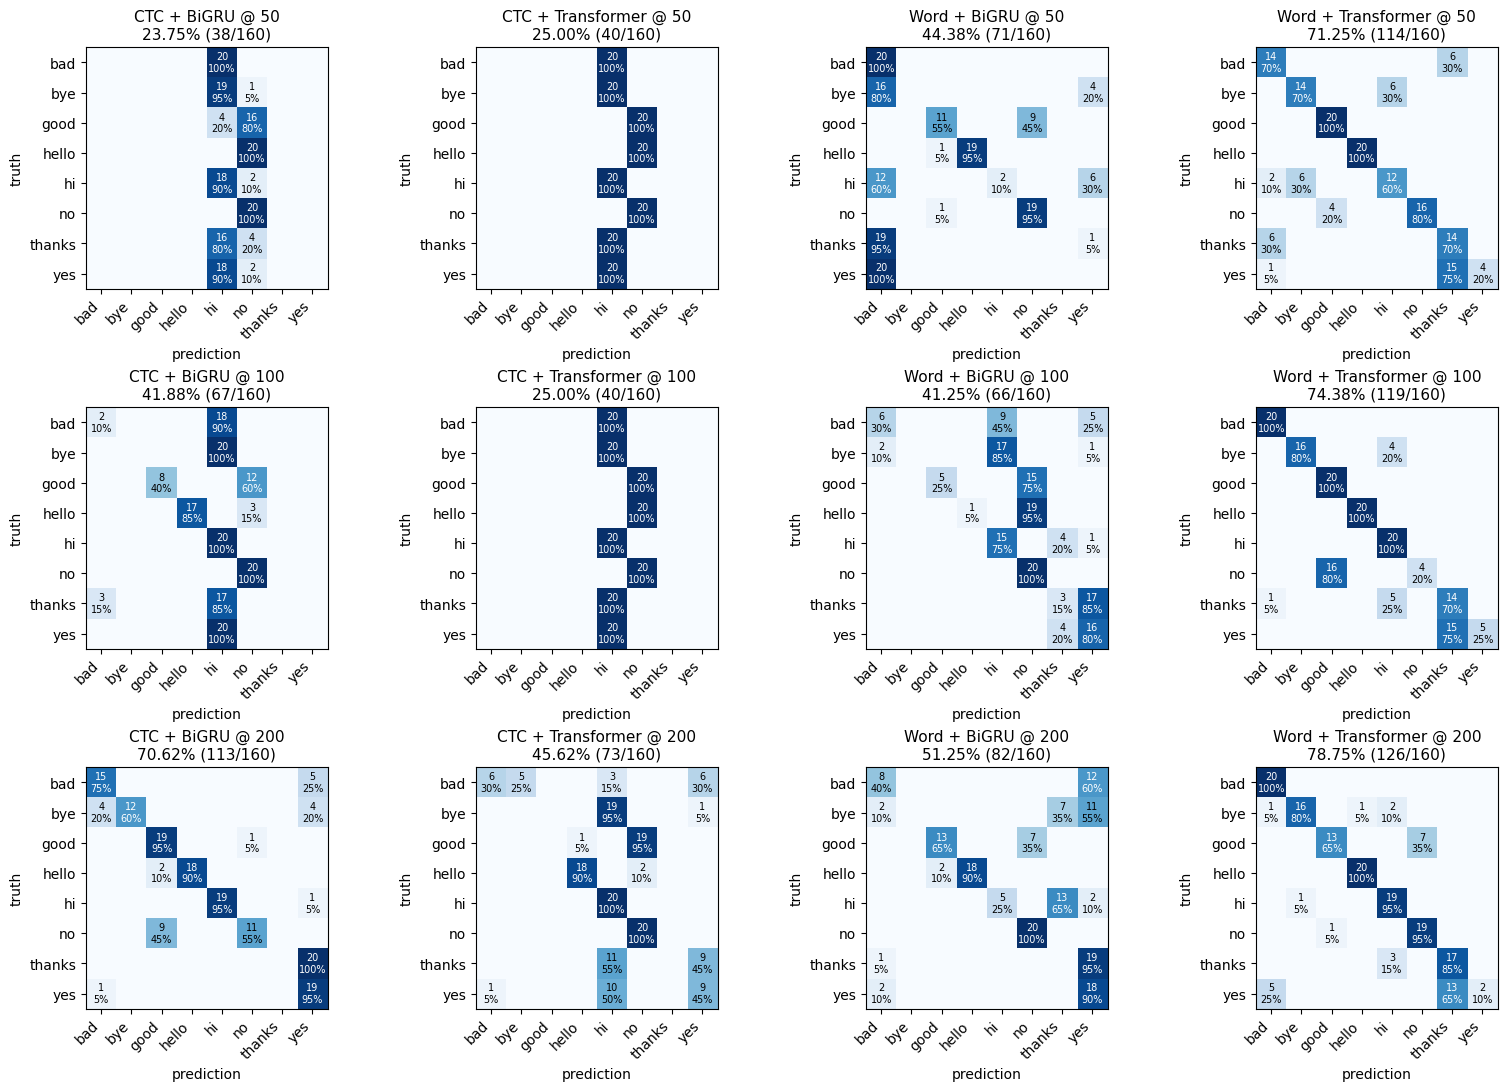

In [5]:
accuracy_grid = sweep.render_grid(
    lambda epoch, key: sweep.format_percent(summaries[(epoch, key)]['accuracy']),
    EPOCH_BUDGETS,
)
count_grid = sweep.render_grid(
    lambda epoch, key: (
        f"{summaries[(epoch, key)]['correct']}/{summaries[(epoch, key)]['predicted']}"
    ),
    EPOCH_BUDGETS,
)
display(Markdown(
    '### Overall test accuracy\n\n' + sweep.format_markdown(accuracy_grid) +
    '\n\n### Clips correct / predicted\n\n' + sweep.format_markdown(count_grid)
))
for (epoch, architecture), summary in summaries.items():
    print(f"{architecture} @ {epoch}: {summary['status_counts']}")

figure = sweep.render_confusion_grid(summaries, EPOCH_BUDGETS, sweep.ARCHITECTURES)
display(figure)
plt.close(figure)

## 6. Save the Evaluation Reports

In [6]:
if SAVE_ARTIFACTS:
    markdown_path, csv_path, per_clip_path = sweep.write_artifacts(
        summaries, OUTPUT_DIR, STEM,
        epochs=EPOCH_BUDGETS,
        per_clip=per_clip,
        context={
            'Evaluation speaker': clips_dir.name,
            'Allow speaker mismatch': ALLOW_SPEAKER_MISMATCH,
            'Clips': len(rows),
            'Source': str(clips_dir),
            'Checkpoints': ', '.join(sorted(set(CHECKPOINT_DIRS.values()))),
        },
    )
    figure_path = OUTPUT_DIR / f'{STEM}_confusion.png'
    figure.savefig(figure_path, dpi=110, bbox_inches='tight')
    for path in (markdown_path, csv_path, per_clip_path, figure_path):
        print(f'Written: {path}')
else:
    print('Report saving disabled (SAVE_ARTIFACTS = False).')

Written: C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak\reports\retrain\epoch_sweep_notebook.md
Written: C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak\reports\retrain\epoch_sweep_notebook.csv
Written: C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak\reports\retrain\epoch_sweep_notebook_predictions.csv
Written: C:\Users\Valente\Desktop\School\Masters\Pattern Recognition System\Practice Module\VisionSpeak\reports\retrain\epoch_sweep_notebook_confusion.png
